# How to plot grid with plotly

Show continuous data, specific colours by region, and outlines.


plotly doesn't seem to be able to use masked arrays, so make sure that either:
+ data in invalid cells have been set to nan, or
+ the colour limits to be plotted exclude the invalid cell values.

## Code setup

In [1]:
import os
from dataclasses import dataclass

# Load data:
import numpy as np  # to load grids
import json  # to load dict
import geojson  # to load and save outlines
import pandas as pd  # for region midpoints

# For colour maps only:
import matplotlib.pyplot as plt
import cmasher as cmr

# Plotting:
import plotly.express as px
import plotly.graph_objects as go
import shapely.plotting  # to plot outlines

# Add path to package:
import sys
sys.path.insert(0,'../')
import isopods.convert
import isopods.outline

In [2]:
@dataclass(frozen=True)
class Paths:
    '''Singleton object for storing paths to data and database.'''

    dir_data: str = '../data'

    dict_filename: str = 'lsoa2011_devon_1k_grid_dict.json'
    lsoa_grid_data_filename: str = 'lsoa2011_devon_1k_grid_data.csv'
    lsoa_grid_mask_filename: str = 'lsoa2011_devon_1k_grid_mask.csv'
    district_grid_data_filename: str = 'district2011_devon_1k_grid_data.csv'
    district_grid_mask_filename: str = 'district2011_devon_1k_grid_mask.csv'
    outline_filename: str = 'districts2011_devon_1k_outlines.geojson'
    midpoints_savename: str = 'districts2011_devon_1k_midpoints.csv'

paths = Paths()

## Load data

In [3]:
# Grid dictionary
p = os.path.join(paths.dir_data, paths.dict_filename)
with open(p, 'r') as f:
    transform_dict = json.load(f)

# Grid array
# LSOA-level:
p_d = os.path.join(paths.dir_data, paths.lsoa_grid_data_filename)
p_m = os.path.join(paths.dir_data, paths.lsoa_grid_mask_filename)
lsoa_grid_data = np.loadtxt(p_d, dtype=str, delimiter=',')
lsoa_grid_mask = np.loadtxt(p_m, dtype=bool, delimiter=',')
arr_lsoa = np.ma.MaskedArray(
    lsoa_grid_data, mask=lsoa_grid_mask, dtype=object)
# District level:
p_d = os.path.join(paths.dir_data, paths.district_grid_data_filename)
p_m = os.path.join(paths.dir_data, paths.district_grid_mask_filename)
district_grid_data = np.loadtxt(p_d, dtype=str, delimiter=',')
district_grid_mask = np.loadtxt(p_m, dtype=bool, delimiter=',')
arr_districts = np.ma.MaskedArray(
    district_grid_data, mask=district_grid_mask, dtype=object)

# Outlines
p = os.path.join(paths.dir_data, paths.outline_filename)
with open(p, 'r') as f:
    gj = geojson.load(f)
dict_polys = isopods.outline.convert_featurecollection_to_dict_polys(gj)

# Midpoints
p = os.path.join(paths.dir_data, paths.midpoints_savename)
df_mids = pd.read_csv(p, index_col='region')

## Setup for plots

Grid extent:

In [4]:
# For plotting the grid with imshow:
extent = (transform_dict['xmin'], transform_dict['xmax'],
          transform_dict['ymin'], transform_dict['ymax'])

# Centres of each cell:
x = isopods.grid.calculate_cell_centres(
    transform_dict['xmin'], transform_dict['xmax'],
    transform_dict['cell_width'])
y = isopods.grid.calculate_cell_centres(
    transform_dict['ymin'], transform_dict['ymax'],
    transform_dict['cell_height'])

Assign random values to LSOA:

In [5]:
# Convert to grid containing this data:
try:
    labels_unique = np.unique(arr_lsoa.compressed())  # masked array
except AttributeError:
    labels_unique = np.unique(arr_lsoa)  # normal array
np.random.seed(42)
np.random.shuffle(labels_unique)
dict_labels_to_data = dict(zip(labels_unique, range(len(labels_unique))))

arr_lsoa_values = isopods.convert.convert_grid_values(
    arr_lsoa, dict_labels_to_data)

# Set masked data to NaN so that plotly doesn't show it:
arr_lsoa_values = arr_lsoa_values.astype(float)
arr_lsoa_values.data[arr_lsoa_values.mask] = np.nan

Generate colours for districts.

In [6]:
try:
    labels_unique = np.unique(arr_districts.compressed())  # masked array
except AttributeError:
    labels_unique = np.unique(arr_districts)  # normal array
colours_rgba = plt.get_cmap('cmr.rainforest_r')(
    np.linspace(0.1, 0.9, len(labels_unique)))
# Convert tuples to strings.
# Drop the alpha or the colour won't display right!
colours = (colours_rgba * 255).astype(int)
colours = ['#%02x%02x%02x' % tuple(c[:3]) for c in colours]
dict_place_colours = dict(zip(labels_unique, colours))
# Check that these colours are strings:
print('Colour type:', type(list(dict_place_colours.values())[0]))

# Colours for heatmap must be assigned to numerical data,
# not region names. The numbers must go from 0 to 1.
# Give each region a number:
dict_region_number = dict(zip(labels_unique,
                              np.linspace(0.0, 1.0, len(labels_unique))))
# Link the colours from before to the numbers:
dict_number_colour = dict([(n, dict_place_colours[r])
                           for r, n in dict_region_number.items()])
# Convert the dictionary into pairs for the plotly heatmap.
colour_tups = [(k, v) for k, v in dict_number_colour.items()]

arr_districts_numbers = isopods.convert.convert_grid_values(
    arr_districts, dict_region_number)

Colour type: <class 'str'>


Convert polygon shapes to lists of x, y coordinates:

In [7]:
dict_polys_xy = isopods.outline.convert_dict_polys_to_coords(dict_polys)

# Check that data is a 2D array, one column for x and one for y:
print(list(dict_polys_xy.values())[0][:5])

[[294000.0 102000.0]
 [294000.0 104000.0]
 [295000.0 104000.0]
 [295000.0 102000.0]
 [294000.0 102000.0]]


## Plots

### imshow with continuous data

Basic version with plotly express:

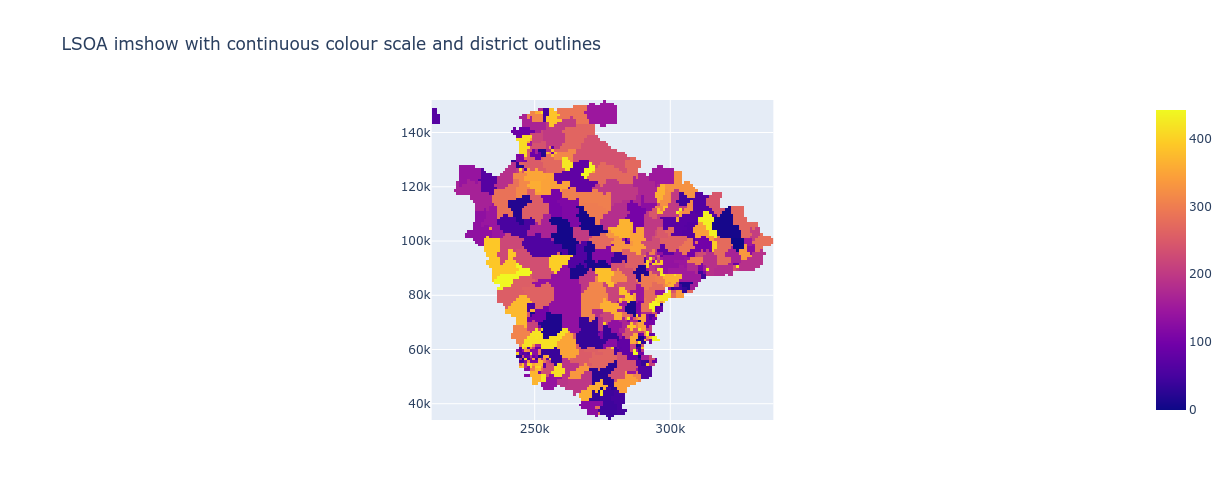

In [8]:
fig = px.imshow(arr_lsoa_values, origin='lower', x=x, y=y, height=500,
                title='LSOA imshow with continuous colour scale '
                      'and district outlines',)
fig.show()

With graph objects:

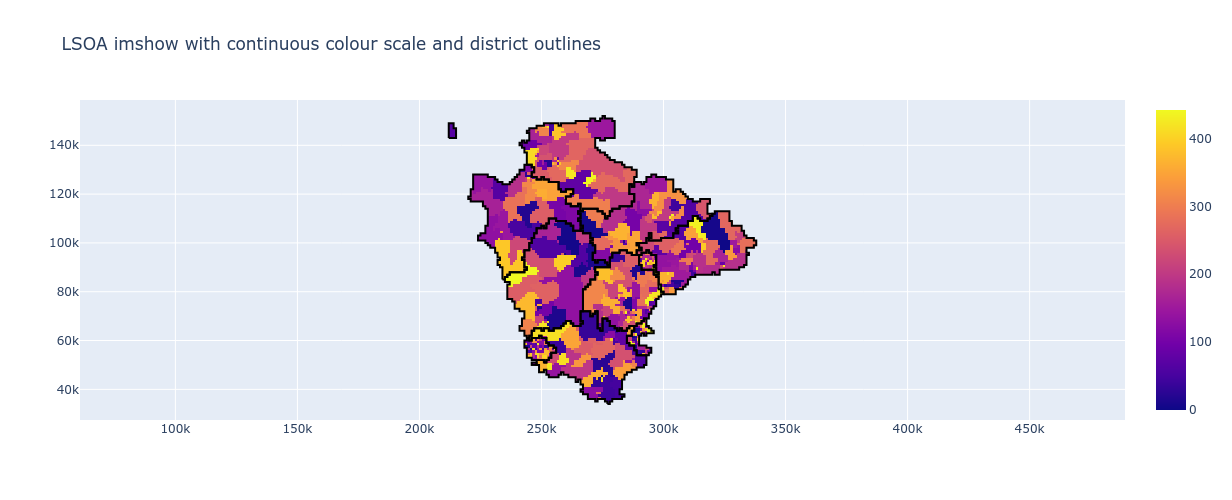

In [9]:
fig = go.Figure()

# Draw gridded data:
# Start point (x0, y0) is the middle of the cell.
fig.add_trace(go.Heatmap(
    z=arr_lsoa_values,
    transpose=False,
    x0=transform_dict['xmin'] + 0.5 * transform_dict['cell_width'],
    dx=transform_dict['cell_width'],
    y0=transform_dict['ymin'] + 0.5 * transform_dict['cell_height'],
    dy=transform_dict['cell_height'],
    # colorscale='viridis',
    # hoverinfo='skip'
))

# Overlay outlines:
for region, coords in dict_polys_xy.items():
    fig.add_trace(go.Scatter(
        x=coords[:, 0],
        y=coords[:, 1],
        line_color='black',
        showlegend=False,
        name=region
    ))

# Figure setup.
fig.update_layout(title_text='LSOA imshow with continuous colour scale '
                             'and district outlines')
fig.update_layout(height=500)
# Equivalent to pyplot set_aspect='equal':
fig.update_yaxes(scaleanchor='x', scaleratio=1)
fig.show()


### imshow with colour lookup


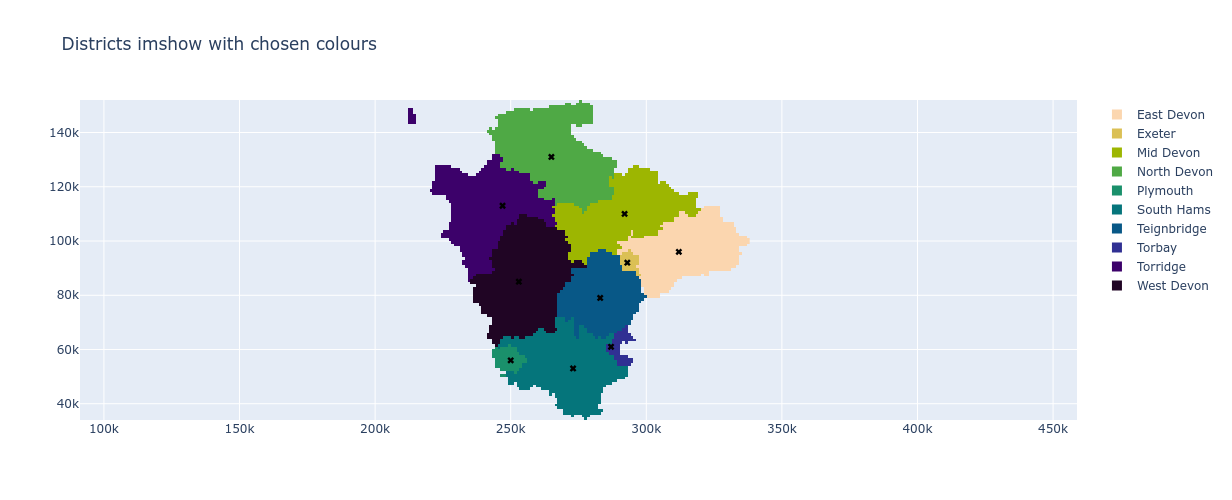

In [10]:
fig = go.Figure()

# Draw gridded data:
# Start point (x0, y0) is the middle of the cell.
fig.add_trace(go.Heatmap(
    z=arr_districts_numbers,
    transpose=False,
    x0=transform_dict['xmin'] + 0.5 * transform_dict['cell_width'],
    dx=transform_dict['cell_width'],
    y0=transform_dict['ymin'] + 0.5 * transform_dict['cell_height'],
    dy=transform_dict['cell_height'],
    colorscale=colour_tups,
    showscale=False,  # arbitrary colour scale so don't show it.
    # hoverinfo='skip'
))

# Add a sneaky invisible marker to make a legend entry:
for region, colour in dict_place_colours.items():
    fig.add_trace(go.Scatter(
        x=[None],
        y=[None],
        mode='markers',
        marker={'color': colour, 'symbol': 'square', 'size': 10},
        name=region,
    ))

# Midpoints:
fig.add_trace(go.Scatter(
    x=df_mids['x_mid'],
    y=df_mids['y_mid'],
    mode='markers',
    marker=dict(color='black', symbol='x'),
    customdata=np.stack([df_mids.index], axis=-1),
    hovertemplate='%{customdata[0]}<extra></extra>',
    showlegend=False,
))

# Figure setup.
fig.update_layout(title_text='Districts imshow with chosen colours')
fig.update_layout(height=500)
# Equivalent to pyplot set_aspect='equal':
fig.update_yaxes(scaleanchor='x', scaleratio=1)
fig.show()


### Filled polygons only

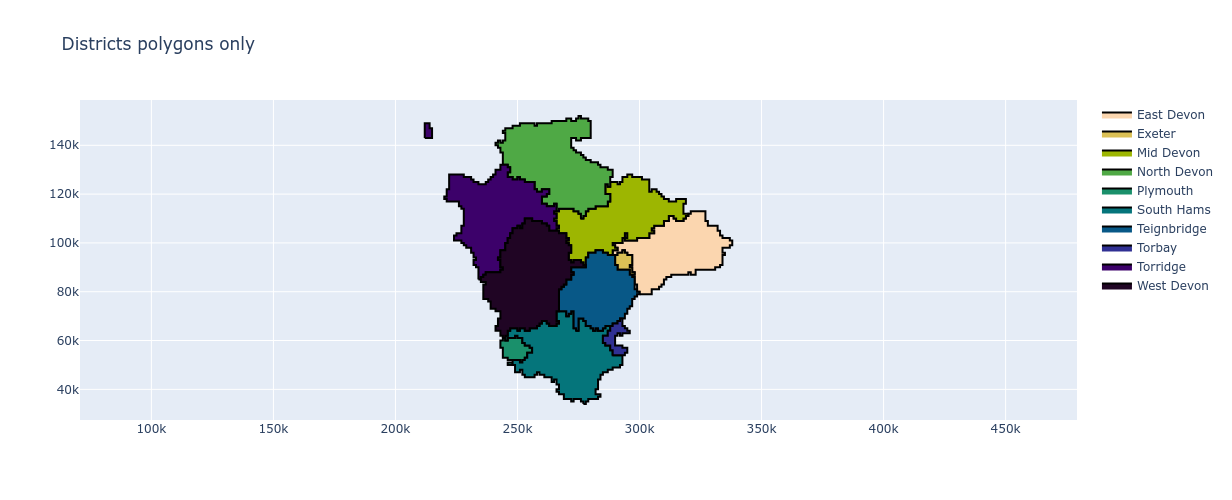

In [11]:
fig = go.Figure()

# Overlay outlines:
for region, coords in dict_polys_xy.items():
    colour = dict_place_colours[region]
    fig.add_trace(go.Scatter(
        x=coords[:, 0],
        y=coords[:, 1],
        fill='toself',
        fillcolor=colour,
        line_color='black',
        showlegend=True,
        name=region
    ))

fig.update_layout(title_text='Districts polygons only')
fig.update_layout(height=500)
# Equivalent to pyplot set_aspect='equal':
fig.update_yaxes(scaleanchor='x', scaleratio=1)
fig.show()